# Movie Master Exploratory Data Analysis

## Overview

The Movie Master Analytics Mart provides a movie-level analytical view of the movie database.

The mart consolidates movie attributes including:

- Movie information
- Release dates
- Popularity
- Budget
- Revenue
- Genres
- Keywords
- Languages
- Production companies
- Production countries

The purpose of this exploratory data analysis is to understand the structure, characteristics, performance, and patterns within the movie portfolio.

## Analytical Grain

The Movie Master is defined at:

> **1 row = 1 movie**

This grain allows movie-level metrics such as budget, revenue, profitability, popularity, and release activity to be analyzed without duplication caused by artist or many-to-many relationships.

## Analytical Objectives

This analysis will investigate:

1. Movie portfolio size and composition.
2. Movie releases over time.
3. Genre distribution.
4. Language distribution.
5. Production company participation.
6. Production country distribution.
7. Budget distribution.
8. Revenue distribution.
9. Movie profitability.
10. Return on investment.
11. Popularity patterns.
12. Relationship between budget and revenue.
13. Relationship between popularity and financial performance.
14. High-performing and underperforming movies.
15. Financial and popularity outliers.

## Key Principle

All movie-level financial and performance metrics will be calculated at the Movie_ID grain.

This prevents double-counting and ensures that analytical results accurately represent individual movies.

# Environment Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Modules Imported Successfully")

Modules Imported Successfully


In [3]:
from sqlalchemy import create_engine
print("SQLAlchemy Engine Created Successfully")

SQLAlchemy Engine Created Successfully


# Load Movie Master

In [4]:
movie_master = pd.read_csv(r"C:\Users\user\Documents\Movie DB SQL Analytics\CSV files\movie_master.csv")

print("Movie Master Data Loaded Successfully")

Movie Master Data Loaded Successfully


In [7]:
movie_master.head()

,Movie_ID,Movie_Title,Release_Date,Popularity,Budget,Revenue,Genres,Keywords,Languages,Production_Companies,Production_Countries
0,5,Four Rooms,1995-12-09 00:00:00.000000,22.876230,4000000,4300000.0,"Comedy,Crime","hotel,new year's eve,witch,bet,hotel room,sper...",English,"Miramax Films,A Band Apart",United States of America
1,11,Star Wars,1977-05-25 00:00:00.000000,126.393695,11000000,775398007.0,"Adventure,Action,Science Fiction","android,galaxy,hermit,death star,lightsaber,je...",English,"Lucasfilm,Twentieth Century Fox Film Corporation",United States of America
2,12,Finding Nemo,2003-05-30 00:00:00.000000,85.688789,94000000,940335536.0,"Animation,Family","father son relationship,harbor,underwater,fish...",English,Pixar Animation Studios,United States of America
3,13,Forrest Gump,1994-07-06 00:00:00.000000,138.133331,55000000,677945399.0,"Drama,Comedy,Romance","vietnam veteran,hippie,mentally disabled,runni...",English,Paramount Pictures,United States of America
4,14,American Beauty,1999-09-15 00:00:00.000000,80.878605,15000000,356296601.0,Drama,"male nudity,female nudity,adultery,midlife cri...",English,"DreamWorks SKG,Jinks/Cohen Company",United States of America


In [8]:
movie_master.shape

(4803, 11)

In [9]:
movie_master.columns

Index(['Movie_ID', 'Movie_Title', 'Release_Date', 'Popularity', 'Budget',
       'Revenue', 'Genres', 'Keywords', 'Languages', 'Production_Companies',
       'Production_Countries'],
      dtype='str')

# Data Profiling

In [10]:
movie_master.info()

<class 'pandas.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Movie_ID              4803 non-null   int64  
 1   Movie_Title           4803 non-null   str    
 2   Release_Date          4802 non-null   str    
 3   Popularity            4803 non-null   float64
 4   Budget                4803 non-null   int64  
 5   Revenue               4803 non-null   float64
 6   Genres                4775 non-null   str    
 7   Keywords              4391 non-null   str    
 8   Languages             4716 non-null   str    
 9   Production_Companies  4452 non-null   str    
 10  Production_Countries  4629 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 412.9 KB


In [11]:
movie_master.describe().T

,count,mean,std,min,25%,50%,75%,max
Movie_ID,4803.0,5.716548e+04,8.869461e+04,5.0,9014.50000,1.462900e+04,5.861050e+04,4.594880e+05
Popularity,4803.0,2.149230e+01,3.181665e+01,0.0,4.66807,1.292159e+01,2.831350e+01,8.755813e+02
Budget,4803.0,2.904504e+07,4.072239e+07,0.0,790000.00000,1.500000e+07,4.000000e+07,3.800000e+08
Revenue,4803.0,8.226064e+07,1.628571e+08,0.0,0.00000,1.917000e+07,9.291719e+07,2.787965e+09


In [12]:
movie_master.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Movie_ID,4803.0,NaN,NaN,NaN,57165.484281,88694.614033,5.0,9014.5,14629.0,58610.5,459488.0
Movie_Title,4803,4800,Batman,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Release_Date,4802,3280,2006-01-01 00:00:00.000000,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Popularity,4803.0,NaN,NaN,NaN,21.492301,31.81665,0.0,4.66807,12.921594,28.313505,875.581305
Budget,4803.0,NaN,NaN,NaN,29045039.875286,40722391.25855,0.0,790000.0,15000000.0,40000000.0,380000000.0
Revenue,4803.0,NaN,NaN,NaN,82260638.651676,162857100.94283,0.0,0.0,19170001.0,92917187.0,2787965087.0
Genres,4775,637,Drama,370,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Keywords,4391,4221,independent film,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Languages,4716,379,English,3187,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Production_Companies,4452,3696,Paramount Pictures,58,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
movie_master.nunique().sort_values()

Languages                379
Production_Countries     425
Budget                   436
Genres                   637
Release_Date            3280
Revenue                 3297
Production_Companies    3696
Keywords                4221
Movie_Title             4800
Popularity              4802
Movie_ID                4803
dtype: int64

In [14]:
missing_values = (
    movie_master.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_values

Keywords                412
Production_Companies    351
Production_Countries    174
Languages                87
Genres                   28
Release_Date              1
Movie_ID                  0
Movie_Title               0
Popularity                0
Budget                    0
Revenue                   0
dtype: int64

In [15]:
missing_percentage = (
    movie_master.isna().mean() * 100
).sort_values(ascending=False)

missing_percentage

Keywords                8.577972
Production_Companies    7.307933
Production_Countries    3.622736
Languages               1.811368
Genres                  0.582969
Release_Date            0.020820
Movie_ID                0.000000
Movie_Title             0.000000
Popularity              0.000000
Budget                  0.000000
Revenue                 0.000000
dtype: float64

# Data Quality Validation

In [16]:
movie_master["Movie_ID"].duplicated().sum()

np.int64(0)

In [17]:
movie_master["Movie_ID"].nunique()

4803

In [18]:
movie_master["Movie_ID"].nunique()

4803

In [21]:
assert len(movie_master) == movie_master["Movie_ID"].nunique()

In [20]:
movie_master["Movie_ID"].isna().sum()

np.int64(0)

# Movie Portfolio Analysis

In [22]:
total_movies = movie_master["Movie_ID"].nunique()

print(f"Total Movies: {total_movies:,}")

Total Movies: 4,803


In [23]:
portfolio_summary = pd.DataFrame({
    "Metric": [
        "Total Movies",
        "Average Popularity",
        "Average Budget",
        "Average Revenue",
        "Median Budget",
        "Median Revenue"
    ],
    "Value": [
        movie_master["Movie_ID"].nunique(),
        movie_master["Popularity"].mean(),
        movie_master["Budget"].mean(),
        movie_master["Revenue"].mean(),
        movie_master["Budget"].median(),
        movie_master["Revenue"].median()
    ]
})

portfolio_summary

,Metric,Value
0,Total Movies,4.803000e+03
1,Average Popularity,2.149230e+01
2,Average Budget,2.904504e+07
3,Average Revenue,8.226064e+07
4,Median Budget,1.500000e+07
5,Median Revenue,1.917000e+07


 # Release & Time Analysis

In [24]:
movie_master["Release_Date"] = pd.to_datetime(
    movie_master["Release_Date"],
    errors="coerce"
)

In [25]:
movie_master["Release_Year"] = (
    movie_master["Release_Date"].dt.year
)

In [26]:
movie_master["Release_Month"] = (
    movie_master["Release_Date"].dt.month
)

In [27]:
movie_master["Release_Decade"] = (
    movie_master["Release_Year"] // 10
) * 10

In [28]:
movies_by_year = (
    movie_master
    .groupby("Release_Year")
    ["Movie_ID"]
    .nunique()
)

movies_by_year.tail(20)

Release_Year
1998.0    133
1999.0    171
2000.0    166
2001.0    183
2002.0    203
2003.0    169
2004.0    204
2005.0    217
2006.0    237
2007.0    195
2008.0    227
2009.0    247
2010.0    225
2011.0    223
2012.0    208
2013.0    231
2014.0    238
2015.0    216
2016.0    104
2017.0      1
Name: Movie_ID, dtype: int64

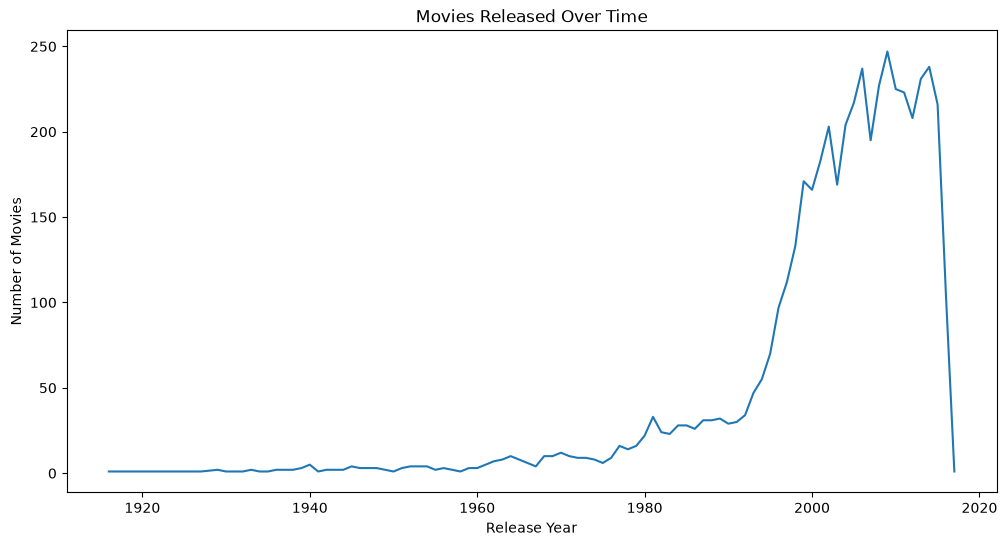

In [29]:
plt.figure(figsize=(12, 6))

movies_by_year.plot()

plt.title("Movies Released Over Time")
plt.xlabel("Release Year")
plt.ylabel("Number of Movies")

plt.show()

# Genre Analysis

In [31]:
genre_df = (
    movie_master[
        ["Movie_ID", "Genres"]
    ]
    .dropna(subset=["Genres"])
    .assign(
        Genre=lambda x: x["Genres"].str.split(",")
    )
    .explode("Genre")
)

genre_df["Genre"] = (
    genre_df["Genre"]
    .str.strip()
)

In [32]:
genre_counts = (
    genre_df["Genre"]
    .value_counts()
)

genre_counts.head(20)

Genre
Drama              2297
Comedy             1722
Thriller           1274
Action             1154
Romance             894
Adventure           790
Crime               696
Science Fiction     535
Horror              519
Family              513
Fantasy             424
Mystery             348
Animation           234
History             197
Music               185
War                 144
Documentary         110
Western              82
Foreign              34
TV Movie              8
Name: count, dtype: int64

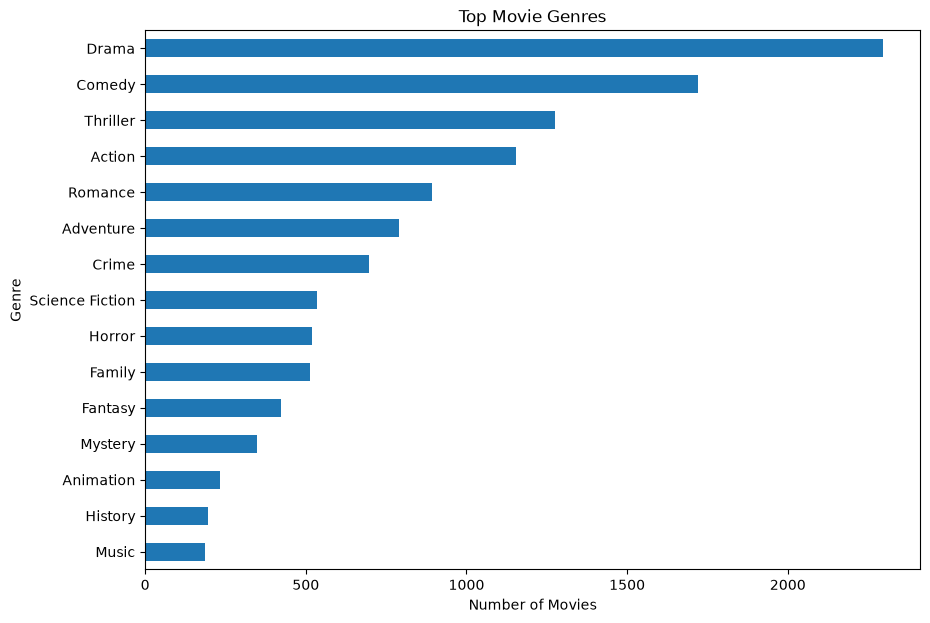

In [33]:
genre_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")

plt.show()

In [34]:
genre_revenue = (
    genre_df
    .merge(
        movie_master[
            ["Movie_ID", "Revenue"]
        ],
        on="Movie_ID",
        how="left"
    )
    .groupby("Genre")
    .agg(
        Movie_Count=("Movie_ID", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

genre_revenue.head(20)

,Movie_Count,Total_Revenue,Average_Revenue
Genre,,,
Adventure,790,1.648416e+11,2.086602e+08
Action,1154,1.629599e+11,1.412131e+08
Comedy,1722,1.227605e+11,7.128950e+07
Drama,2297,1.197110e+11,5.211623e+07
Thriller,1274,1.032504e+11,8.104429e+07
Family,513,8.328324e+10,1.623455e+08
Fantasy,424,8.198220e+10,1.933542e+08
Science Fiction,535,8.156424e+10,1.524565e+08
Romance,894,5.364214e+10,6.000239e+07


# Language Analysis

In [35]:
language_df = (
    movie_master[
        ["Movie_ID", "Languages"]
    ]
    .dropna(subset=["Languages"])
    .assign(
        Language=lambda x: x["Languages"].str.split(",")
    )
    .explode("Language")
)

language_df["Language"] = (
    language_df["Language"]
    .str.strip()
)

In [36]:
language_counts = (
    language_df["Language"]
    .value_counts()
)

language_counts.head(20)

Language
English      4485
Frantais      437
Espa±ol       351
Deutsch       262
???           192
Italiano      188
P??????       185
???????       108
PortuguOs      68
Polski         53
Latin          52
????????       52
??????         52
??? / ???      48
Magyar         42
?esk²          38
???/???        31
svenska        22
?????          19
Tnrkte         18
Name: count, dtype: int64

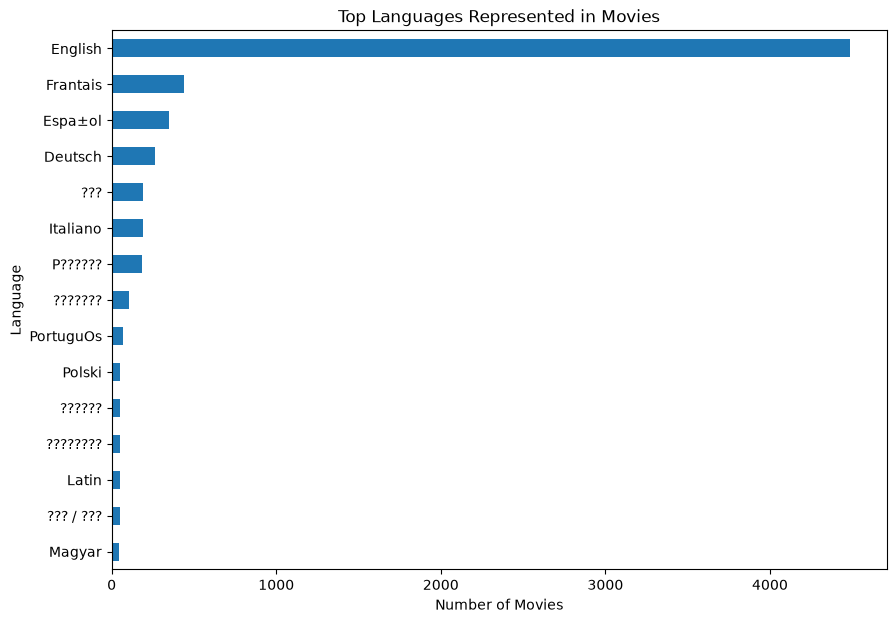

In [37]:
language_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top Languages Represented in Movies")
plt.xlabel("Number of Movies")
plt.ylabel("Language")

plt.show()

# Production Company Analysis

In [40]:
company_df = (
    movie_master[
        ["Movie_ID", "Production_Companies"]
    ]
    .dropna(subset=["Production_Companies"])
    .assign(
        Production_Company=lambda x:
            x["Production_Companies"].str.split(",")
    )
    .explode("Production_Company")
)

company_df["Production_Company"] = (
    company_df["Production_Company"]
    .str.strip()
)

In [41]:
company_counts = (
    company_df["Production_Company"]
    .value_counts()
)

company_counts.head(20)

Production_Company
Warner Bros.                              319
Universal Pictures                        311
Paramount Pictures                        285
Twentieth Century Fox Film Corporation    222
Columbia Pictures                         201
New Line Cinema                           165
Metro-Goldwyn-Mayer (MGM)                 122
Touchstone Pictures                       118
Walt Disney Pictures                      114
Relativity Media                          102
Columbia Pictures Corporation              96
Miramax Films                              94
Village Roadshow Pictures                  81
DreamWorks SKG                             79
Canal+                                     75
United Artists                             75
Regency Enterprises                        69
Fox Searchlight Pictures                   64
Dune Entertainment                         59
Lionsgate                                  56
Name: count, dtype: int64

In [42]:
company_revenue = (
    company_df
    .merge(
        movie_master[
            ["Movie_ID", "Revenue"]
        ],
        on="Movie_ID",
        how="left"
    )
    .groupby("Production_Company")
    .agg(
        Movie_Count=("Movie_ID", "nunique"),
        Total_Revenue=("Revenue", "sum"),
        Average_Revenue=("Revenue", "mean")
    )
    .sort_values(
        "Total_Revenue",
        ascending=False
    )
)

company_revenue.head(20)

,Movie_Count,Total_Revenue,Average_Revenue
Production_Company,,,
Warner Bros.,319,4.915575e+10,1.540933e+08
Universal Pictures,311,4.258847e+10,1.369404e+08
Paramount Pictures,285,4.087852e+10,1.434334e+08
Twentieth Century Fox Film Corporation,222,3.935715e+10,1.772845e+08
Walt Disney Pictures,114,2.868326e+10,2.516075e+08
Columbia Pictures,201,2.859963e+10,1.422867e+08
New Line Cinema,165,1.944487e+10,1.178477e+08
Amblin Entertainment,49,1.609084e+10,3.283844e+08
DreamWorks SKG,79,1.438453e+10,1.820827e+08


# Production Country Analysis

In [44]:
country_df = (
    movie_master[
        ["Movie_ID", "Production_Countries"]
    ]
    .dropna(subset=["Production_Countries"])
    .assign(
        Production_Country=lambda x:
            x["Production_Countries"].str.split(",")
    )
    .explode("Production_Country")
)

country_df["Production_Country"] = (
    country_df["Production_Country"]
    .str.strip()
)

In [45]:
country_counts = (
    country_df["Production_Country"]
    .value_counts()
)

country_counts.head(20)

Production_Country
United States of America    3956
United Kingdom               636
Deutschland                  324
Fran??aise                   306
Canada                       261
??????                       194
Australia                    110
Italiana                      72
Espa??a                       71
???????                       60
????????                      58
Ireland                       37
Mexicanos                     30
New Zealand                   28
Belgi+½                       25
??esk?? republika             24
Danmark                       20
South Africa                  20
Sverige                       19
Switzerland                   19
Name: count, dtype: int64

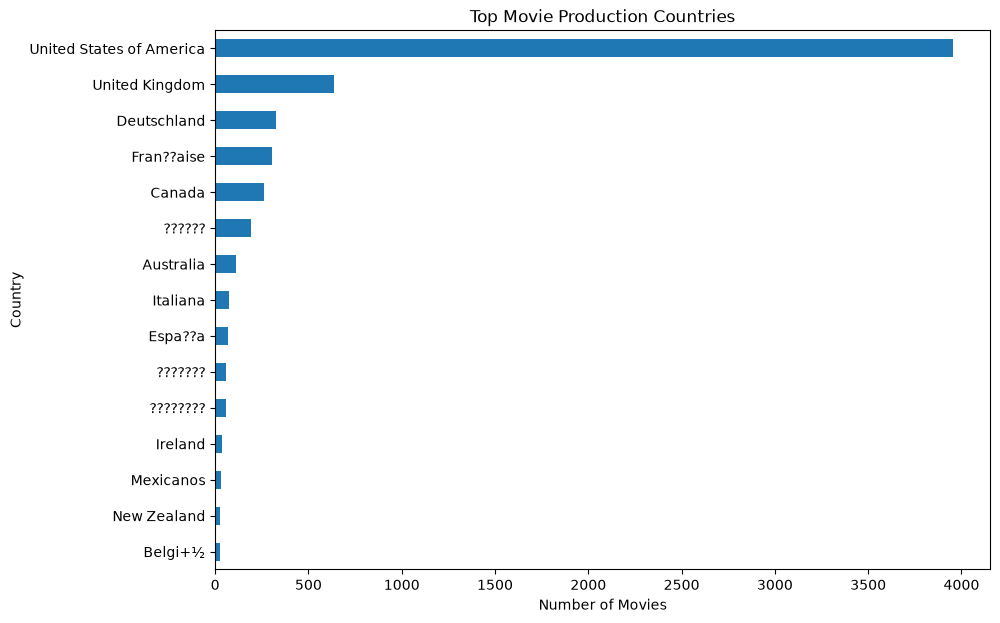

In [46]:
country_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Top Movie Production Countries")
plt.xlabel("Number of Movies")
plt.ylabel("Country")

plt.show()

# Budget Analysis

In [47]:
movie_master["Budget"].describe()

count    4.803000e+03
mean     2.904504e+07
std      4.072239e+07
min      0.000000e+00
25%      7.900000e+05
50%      1.500000e+07
75%      4.000000e+07
max      3.800000e+08
Name: Budget, dtype: float64

In [48]:
(movie_master["Budget"] == 0).sum()

np.int64(1037)

In [50]:
(movie_master["Budget"] < 0).sum()

np.int64(0)

In [51]:
movie_master["Budget"].isna().sum()

np.int64(0)

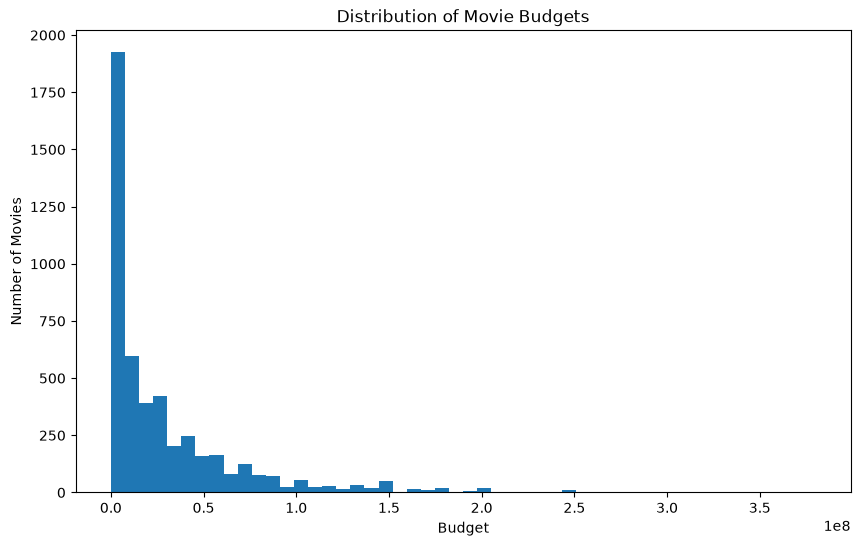

In [52]:
plt.figure(figsize=(10, 6))

plt.hist(
    movie_master["Budget"],
    bins=50
)

plt.title("Distribution of Movie Budgets")
plt.xlabel("Budget")
plt.ylabel("Number of Movies")

plt.show()

In [53]:
print(
    "Mean Budget:",
    movie_master["Budget"].mean()
)

print(
    "Median Budget:",
    movie_master["Budget"].median()
)

Mean Budget: 29045039.87528628
Median Budget: 15000000.0


# Revenue Analysis

In [54]:
movie_master["Revenue"].describe()

count    4.803000e+03
mean     8.226064e+07
std      1.628571e+08
min      0.000000e+00
25%      0.000000e+00
50%      1.917000e+07
75%      9.291719e+07
max      2.787965e+09
Name: Revenue, dtype: float64

In [55]:
(movie_master["Revenue"] == 0).sum()

np.int64(1427)

In [56]:
(movie_master["Revenue"] < 0).sum()

np.int64(0)

In [57]:
top_revenue_movies = (
    movie_master[
        [
            "Movie_ID",
            "Movie_Title",
            "Budget",
            "Revenue",
            "Popularity"
        ]
    ]
    .sort_values(
        "Revenue",
        ascending=False
    )
    .head(20)
)

top_revenue_movies

,Movie_ID,Movie_Title,Budget,Revenue,Popularity
2702,19995,Avatar,237000000,2.787965e+09,150.437577
256,597,Titanic,200000000,1.845034e+09,100.025899
2861,24428,The Avengers,220000000,1.519558e+09,144.448633
4108,135397,Jurassic World,150000000,1.513529e+09,418.708552
4204,168259,Furious 7,190000000,1.506249e+09,102.322217
3983,99861,Avengers: Age of Ultron,280000000,1.405404e+09,134.279229
4025,109445,Frozen,150000000,1.274219e+09,165.125366
3704,68721,Iron Man 3,200000000,1.215440e+09,77.682080
4327,211672,Minions,74000000,1.156731e+09,875.581305
4519,271110,Captain America: Civil War,250000000,1.153304e+09,198.372395


In [58]:
top_revenue_movies = (
    movie_master[
        [
            "Movie_ID",
            "Movie_Title",
            "Budget",
            "Revenue",
            "Popularity"
        ]
    ]
    .sort_values(
        "Revenue",
        ascending=False
    )
    .head(20)
)

top_revenue_movies

,Movie_ID,Movie_Title,Budget,Revenue,Popularity
2702,19995,Avatar,237000000,2.787965e+09,150.437577
256,597,Titanic,200000000,1.845034e+09,100.025899
2861,24428,The Avengers,220000000,1.519558e+09,144.448633
4108,135397,Jurassic World,150000000,1.513529e+09,418.708552
4204,168259,Furious 7,190000000,1.506249e+09,102.322217
3983,99861,Avengers: Age of Ultron,280000000,1.405404e+09,134.279229
4025,109445,Frozen,150000000,1.274219e+09,165.125366
3704,68721,Iron Man 3,200000000,1.215440e+09,77.682080
4327,211672,Minions,74000000,1.156731e+09,875.581305
4519,271110,Captain America: Civil War,250000000,1.153304e+09,198.372395


# Profitability & ROI

In [59]:
movie_master["Profit"] = (
    movie_master["Revenue"]
    - movie_master["Budget"]
)

In [60]:
movie_master["ROI"] = np.where(
    movie_master["Budget"] > 0,
    (
        movie_master["Revenue"]
        - movie_master["Budget"]
    ) / movie_master["Budget"],
    np.nan
)

In [61]:
movie_master["ROI_Percentage"] = (
    movie_master["ROI"] * 100
)

In [62]:
movie_master[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit",
        "ROI_Percentage"
    ]
].sort_values(
    "Profit",
    ascending=False
).head(20)

,Movie_Title,Budget,Revenue,Profit,ROI_Percentage
2702,Avatar,237000000,2.787965e+09,2.550965e+09,1076.356577
256,Titanic,200000000,1.845034e+09,1.645034e+09,822.517094
4108,Jurassic World,150000000,1.513529e+09,1.363529e+09,909.019207
4204,Furious 7,190000000,1.506249e+09,1.316249e+09,692.762821
2861,The Avengers,220000000,1.519558e+09,1.299558e+09,590.708141
3983,Avengers: Age of Ultron,280000000,1.405404e+09,1.125404e+09,401.929891
4025,Frozen,150000000,1.274219e+09,1.124219e+09,749.479339
4327,Minions,74000000,1.156731e+09,1.082731e+09,1463.149949
56,The Lord of the Rings: The Return of the King,94000000,1.118889e+09,1.024889e+09,1090.307424
3704,Iron Man 3,200000000,1.215440e+09,1.015440e+09,507.719997


In [63]:
roi_analysis = movie_master[
    movie_master["Budget"] >= 100000
].copy()

In [64]:
roi_analysis[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit",
        "ROI_Percentage"
    ]
].sort_values(
    "ROI_Percentage",
    ascending=False
).head(20)

,Movie_Title,Budget,Revenue,Profit,ROI_Percentage
4616,The Gallows,100000,42664410.0,42564410.0,42564.410000
34,Open Water,130000,54667954.0,54537954.0,41952.272308
798,Bambi,858000,267447150.0,266589150.0,31070.996503
3726,The Stewardesses,100000,27000000.0,26900000.0,26900.000000
1654,Night of the Living Dead,114000,30000000.0,29886000.0,26215.789474
1403,Mad Max,400000,100000000.0,99600000.0,24900.000000
422,Halloween,300000,70000000.0,69700000.0,23233.333333
378,American Graffiti,777000,140000000.0,139223000.0,17918.018018
929,Once,160000,20710513.0,20550513.0,12844.070625
178,Snow White and the Seven Dwarfs,1488423,184925486.0,183437063.0,12324.256142


# Profitability Classification

In [65]:
movie_master["Profitability_Status"] = np.select(
    [
        movie_master["Profit"] > 0,
        movie_master["Profit"] == 0,
        movie_master["Profit"] < 0
    ],
    [
        "Profitable",
        "Break-even",
        "Loss"
    ],
    default="Unknown"
)

In [66]:
movie_master[
    "Profitability_Status"
].value_counts()

Profitability_Status
Profitable    2585
Loss          1326
Break-even     892
Name: count, dtype: int64

In [67]:
movie_master[
    "Profitability_Status"
].value_counts(
    normalize=True
) * 100

Profitability_Status
Profitable    53.820529
Loss          27.607745
Break-even    18.571726
Name: proportion, dtype: float64

# Popularity Analysis

In [68]:
movie_master["Popularity"].describe()

count    4803.000000
mean       21.492301
std        31.816650
min         0.000000
25%         4.668070
50%        12.921594
75%        28.313505
max       875.581305
Name: Popularity, dtype: float64

In [69]:
top_popular_movies = (
    movie_master[
        [
            "Movie_ID",
            "Movie_Title",
            "Popularity",
            "Budget",
            "Revenue"
        ]
    ]
    .sort_values(
        "Popularity",
        ascending=False
    )
    .head(20)
)

top_popular_movies

,Movie_ID,Movie_Title,Popularity,Budget,Revenue
4327,211672,Minions,875.581305,74000000,1.156731e+09
4170,157336,Interstellar,724.247784,165000000,6.751200e+08
4593,293660,Deadpool,514.569956,58000000,7.831130e+08
4057,118340,Guardians of the Galaxy,481.098624,170000000,7.733286e+08
3801,76341,Mad Max: Fury Road,434.278564,150000000,3.788583e+08
4108,135397,Jurassic World,418.708552,150000000,1.513529e+09
9,22,Pirates of the Caribbean: The Curse of the Bla...,271.972889,140000000,6.550112e+08
4062,119450,Dawn of the Planet of the Apes,243.791743,170000000,7.106446e+08
4093,131631,The Hunger Games: Mockingjay - Part 1,206.227151,125000000,7.521002e+08
4230,177572,Big Hero 6,203.734590,165000000,6.521054e+08


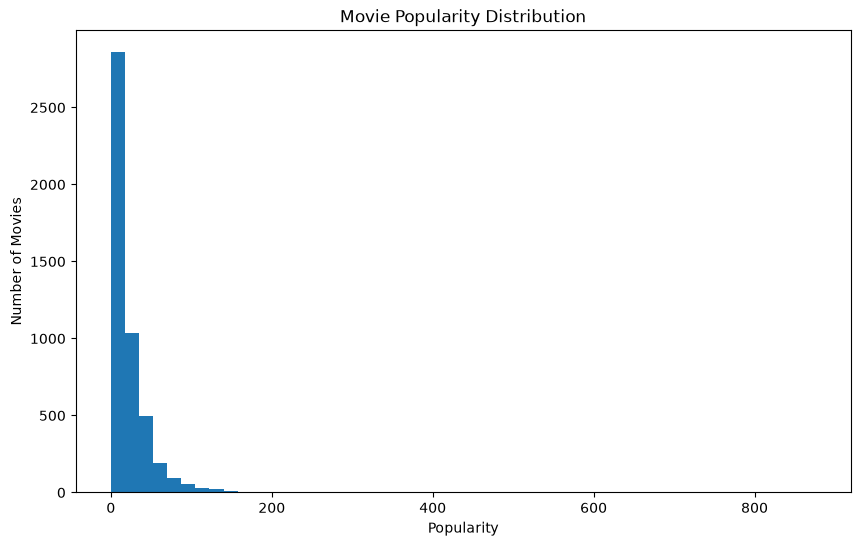

In [70]:
plt.figure(figsize=(10, 6))

plt.hist(
    movie_master["Popularity"].dropna(),
    bins=50
)

plt.title("Movie Popularity Distribution")
plt.xlabel("Popularity")
plt.ylabel("Number of Movies")

plt.show()

# Budget vs Revenue

In [71]:
movie_master[
    ["Budget", "Revenue"]
].corr()

,Budget,Revenue
Budget,1.000000,0.730823
Revenue,0.730823,1.000000


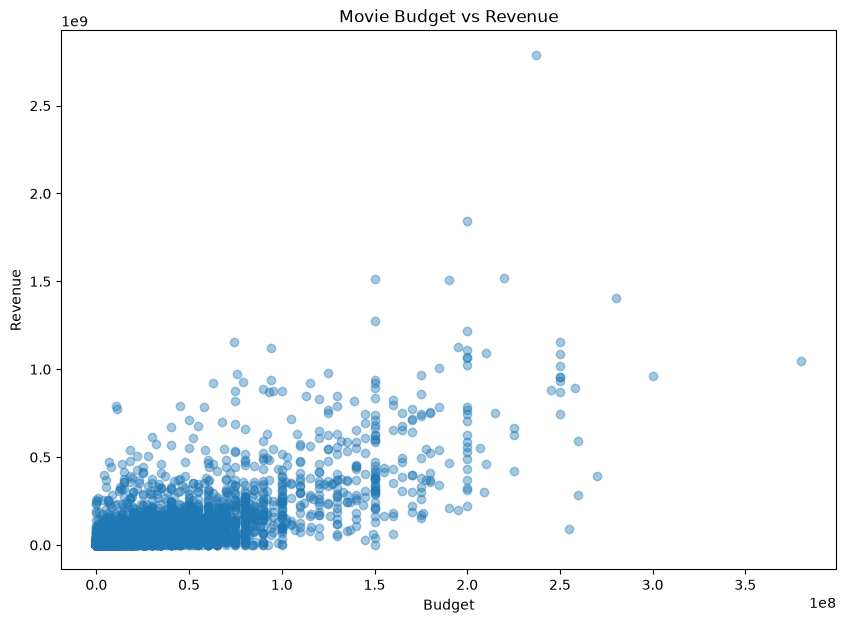

In [72]:
plt.figure(figsize=(10, 7))

plt.scatter(
    movie_master["Budget"],
    movie_master["Revenue"],
    alpha=0.4
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Budget")
plt.ylabel("Revenue")

plt.show()

# Budget vs Profit

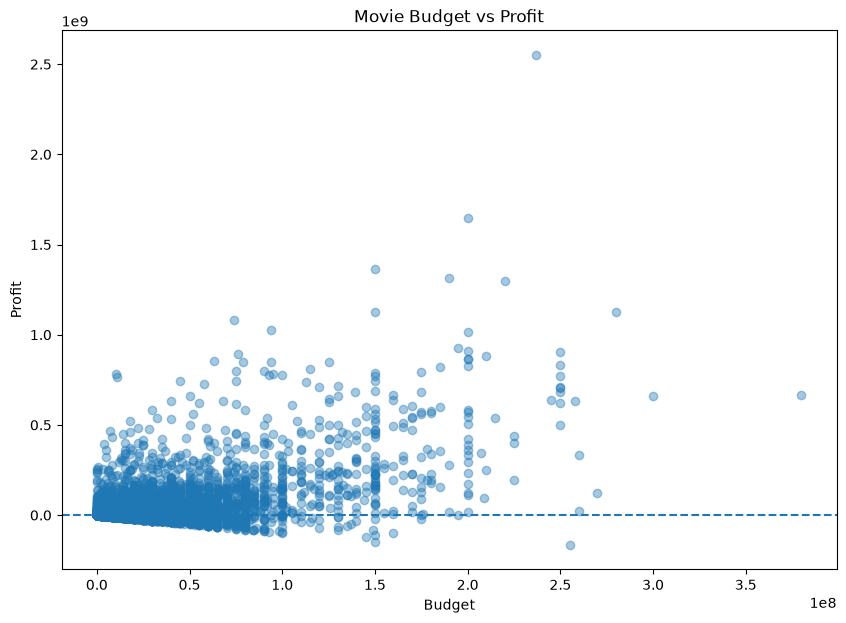

In [73]:
plt.figure(figsize=(10, 7))

plt.scatter(
    movie_master["Budget"],
    movie_master["Profit"],
    alpha=0.4
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Movie Budget vs Profit")
plt.xlabel("Budget")
plt.ylabel("Profit")

plt.show()

# Movie Performance Segmentation

In [75]:
revenue_bins = pd.qcut(
    movie_master["Revenue"],
    q=4,
    duplicates="drop"
)

performance_labels = [
    "Low",
    "Medium",
    "High",
    "Very High"
]

movie_master["Revenue_Performance"] = revenue_bins.cat.rename_categories(
    performance_labels[:len(revenue_bins.cat.categories)]
)

In [76]:
movie_master[
    "Revenue_Performance"
].value_counts(
    sort=False
)

Revenue_Performance
Low       2402
Medium    1200
High      1201
Name: count, dtype: int64

In [77]:
movie_master["Popularity_Performance"] = pd.qcut(
    movie_master["Popularity"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ],
    duplicates="drop"
)

In [78]:
movie_master[
    "Popularity_Performance"
].value_counts(
    sort=False
)

Popularity_Performance
Low          1201
Medium       1201
High         1200
Very High    1201
Name: count, dtype: int64

# High Popularity / Low Revenue Movies

In [79]:
high_popularity = movie_master[
    movie_master["Popularity"]
    >= movie_master["Popularity"].quantile(0.75)
]

low_revenue = movie_master[
    movie_master["Revenue"]
    <= movie_master["Revenue"].quantile(0.25)
]

high_pop_low_revenue = high_popularity.merge(
    low_revenue[
        ["Movie_ID"]
    ],
    on="Movie_ID"
)

In [80]:
high_pop_low_revenue[
    [
        "Movie_Title",
        "Popularity",
        "Budget",
        "Revenue",
        "Profit"
    ]
].sort_values(
    "Popularity",
    ascending=False
).head(20)

,Movie_Title,Popularity,Budget,Revenue,Profit
14,Automata,49.808505,7000000,0.0,-7000000.0
1,Once Upon a Time in America,49.336397,30000000,0.0,-30000000.0
9,Insidious: Chapter 2,48.375848,5000000,0.0,-5000000.0
15,Wild Card,48.034300,30000000,0.0,-30000000.0
11,RED 2,44.343330,84000000,0.0,-84000000.0
7,The Last Stand,43.882857,30000000,0.0,-30000000.0
0,Brazil,41.089863,15000000,0.0,-15000000.0
5,Remember Me,36.764666,20000000,0.0,-20000000.0
2,Army of Darkness,33.758281,11000000,0.0,-11000000.0
6,Tinker Tailor Soldier Spy,33.649652,30000000,0.0,-30000000.0


# High Revenue / Low Popularity

In [81]:
high_revenue = movie_master[
    movie_master["Revenue"]
    >= movie_master["Revenue"].quantile(0.75)
]

low_popularity = movie_master[
    movie_master["Popularity"]
    <= movie_master["Popularity"].quantile(0.25)
]

high_revenue_low_popularity = high_revenue.merge(
    low_popularity[
        ["Movie_ID"]
    ],
    on="Movie_ID"
)

In [82]:
high_revenue_low_popularity[
    [
        "Movie_Title",
        "Popularity",
        "Budget",
        "Revenue",
        "Profit"
    ]
].sort_values(
    "Revenue",
    ascending=False
).head(20)

,Movie_Title,Popularity,Budget,Revenue,Profit
2,Home Alone,2.186927,18000000,476684675.0,458684675.0
6,X-Men: The Last Stand,3.857526,210000000,459359555.0,249359555.0
5,X2,2.871739,110000000,407711549.0,297711549.0
1,Jurassic Park III,1.859364,93000000,368780809.0,275780809.0
7,X-Men: First Class,3.195174,160000000,353624124.0,193624124.0
4,Resident Evil: Afterlife,2.143764,60000000,300228084.0,240228084.0
0,The Lost World: Jurassic Park,2.502487,73000000,229074524.0,156074524.0
3,"Legally Blonde 2: Red, White & Blonde",4.340616,45000000,124914842.0,79914842.0


# Outlier Analysis

In [83]:
def detect_outliers(df, column):

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    return outliers

In [84]:
revenue_outliers = detect_outliers(
    movie_master,
    "Revenue"
)

revenue_outliers.shape

(472, 20)

In [85]:
budget_outliers = detect_outliers(
    movie_master,
    "Budget"
)

budget_outliers.shape

(321, 20)

# Correlation Analysis

In [86]:
financial_columns = [
    "Budget",
    "Revenue",
    "Profit",
    "ROI",
    "Popularity"
]

correlation_matrix = (
    movie_master[
        financial_columns
    ]
    .corr()
)

correlation_matrix

,Budget,Revenue,Profit,ROI,Popularity
Budget,1.000000,0.730823,0.575852,-0.015766,0.505414
Revenue,0.730823,1.000000,0.978881,-0.009684,0.644724
Profit,0.575852,0.978881,1.000000,-0.006968,0.620854
ROI,-0.015766,-0.009684,-0.006968,1.000000,0.000214
Popularity,0.505414,0.644724,0.620854,0.000214,1.000000


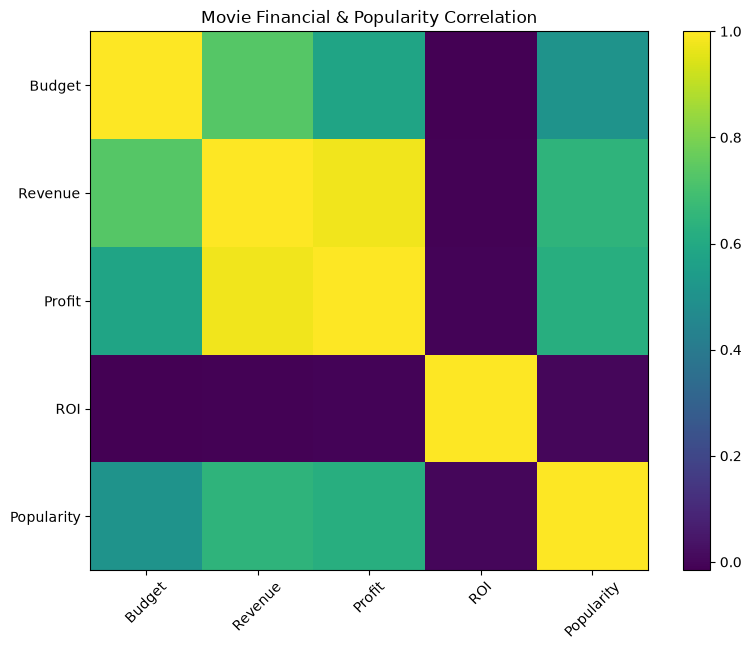

In [87]:
plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.xticks(
    range(len(financial_columns)),
    financial_columns,
    rotation=45
)

plt.yticks(
    range(len(financial_columns)),
    financial_columns
)

plt.colorbar()

plt.title(
    "Movie Financial & Popularity Correlation"
)

plt.show()

# Top and Bottom Performers

In [88]:
movie_master.nlargest(
    20,
    "Revenue"
)[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit",
        "ROI_Percentage",
        "Popularity"
    ]
]

,Movie_Title,Budget,Revenue,Profit,ROI_Percentage,Popularity
2702,Avatar,237000000,2.787965e+09,2.550965e+09,1076.356577,150.437577
256,Titanic,200000000,1.845034e+09,1.645034e+09,822.517094,100.025899
2861,The Avengers,220000000,1.519558e+09,1.299558e+09,590.708141,144.448633
4108,Jurassic World,150000000,1.513529e+09,1.363529e+09,909.019207,418.708552
4204,Furious 7,190000000,1.506249e+09,1.316249e+09,692.762821,102.322217
3983,Avengers: Age of Ultron,280000000,1.405404e+09,1.125404e+09,401.929891,134.279229
4025,Frozen,150000000,1.274219e+09,1.124219e+09,749.479339,165.125366
3704,Iron Man 3,200000000,1.215440e+09,1.015440e+09,507.719997,77.682080
4327,Minions,74000000,1.156731e+09,1.082731e+09,1463.149949,875.581305
4519,Captain America: Civil War,250000000,1.153304e+09,9.033045e+08,361.321798,198.372395


In [89]:
movie_master.nlargest(
    20,
    "Profit"
)[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit",
        "ROI_Percentage"
    ]
]

,Movie_Title,Budget,Revenue,Profit,ROI_Percentage
2702,Avatar,237000000,2.787965e+09,2.550965e+09,1076.356577
256,Titanic,200000000,1.845034e+09,1.645034e+09,822.517094
4108,Jurassic World,150000000,1.513529e+09,1.363529e+09,909.019207
4204,Furious 7,190000000,1.506249e+09,1.316249e+09,692.762821
2861,The Avengers,220000000,1.519558e+09,1.299558e+09,590.708141
3983,Avengers: Age of Ultron,280000000,1.405404e+09,1.125404e+09,401.929891
4025,Frozen,150000000,1.274219e+09,1.124219e+09,749.479339
4327,Minions,74000000,1.156731e+09,1.082731e+09,1463.149949
56,The Lord of the Rings: The Return of the King,94000000,1.118889e+09,1.024889e+09,1090.307424
3704,Iron Man 3,200000000,1.215440e+09,1.015440e+09,507.719997


In [90]:
roi_analysis.nlargest(
    20,
    "ROI_Percentage"
)[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit",
        "ROI_Percentage"
    ]
]

,Movie_Title,Budget,Revenue,Profit,ROI_Percentage
4616,The Gallows,100000,42664410.0,42564410.0,42564.410000
34,Open Water,130000,54667954.0,54537954.0,41952.272308
798,Bambi,858000,267447150.0,266589150.0,31070.996503
3726,The Stewardesses,100000,27000000.0,26900000.0,26900.000000
1654,Night of the Living Dead,114000,30000000.0,29886000.0,26215.789474
1403,Mad Max,400000,100000000.0,99600000.0,24900.000000
422,Halloween,300000,70000000.0,69700000.0,23233.333333
378,American Graffiti,777000,140000000.0,139223000.0,17918.018018
929,Once,160000,20710513.0,20550513.0,12844.070625
178,Snow White and the Seven Dwarfs,1488423,184925486.0,183437063.0,12324.256142


In [91]:
movie_master.nsmallest(
    20,
    "Revenue"
)[
    [
        "Movie_Title",
        "Budget",
        "Revenue",
        "Profit"
    ]
]

,Movie_Title,Budget,Revenue,Profit
22,Brazil,15000000,0.0,-15000000.0
141,The Celebration,1300000,0.0,-1300000.0
143,Once Upon a Time in America,30000000,0.0,-30000000.0
154,Inspector Gadget,75000000,0.0,-75000000.0
158,Summer Storm,2700000,0.0,-2700000.0
177,The Straight Story,10000000,0.0,-10000000.0
191,Maria Full of Grace,0,0.0,0.0
198,As It Is in Heaven,0,0.0,0.0
199,My Own Private Idaho,2500000,0.0,-2500000.0
203,Monsoon Wedding,0,0.0,0.0


# Executive Movie Portfolio Summary

In [92]:
movie_summary = pd.DataFrame({
    "Metric": [
        "Total Movies",
        "Average Budget",
        "Median Budget",
        "Average Revenue",
        "Median Revenue",
        "Average Popularity",
        "Median Popularity",
        "Total Revenue",
        "Total Profit",
        "Profitable Movies",
        "Loss-Making Movies"
    ],
    "Value": [
        movie_master["Movie_ID"].nunique(),
        movie_master["Budget"].mean(),
        movie_master["Budget"].median(),
        movie_master["Revenue"].mean(),
        movie_master["Revenue"].median(),
        movie_master["Popularity"].mean(),
        movie_master["Popularity"].median(),
        movie_master["Revenue"].sum(),
        movie_master["Profit"].sum(),
        (movie_master["Profit"] > 0).sum(),
        (movie_master["Profit"] < 0).sum()
    ]
})

movie_summary

,Metric,Value
0,Total Movies,4.803000e+03
1,Average Budget,2.904504e+07
2,Median Budget,1.500000e+07
3,Average Revenue,8.226064e+07
4,Median Revenue,1.917000e+07
5,Average Popularity,2.149230e+01
6,Median Popularity,1.292159e+01
7,Total Revenue,3.950978e+11
8,Total Profit,2.555945e+11
9,Profitable Movies,2.585000e+03


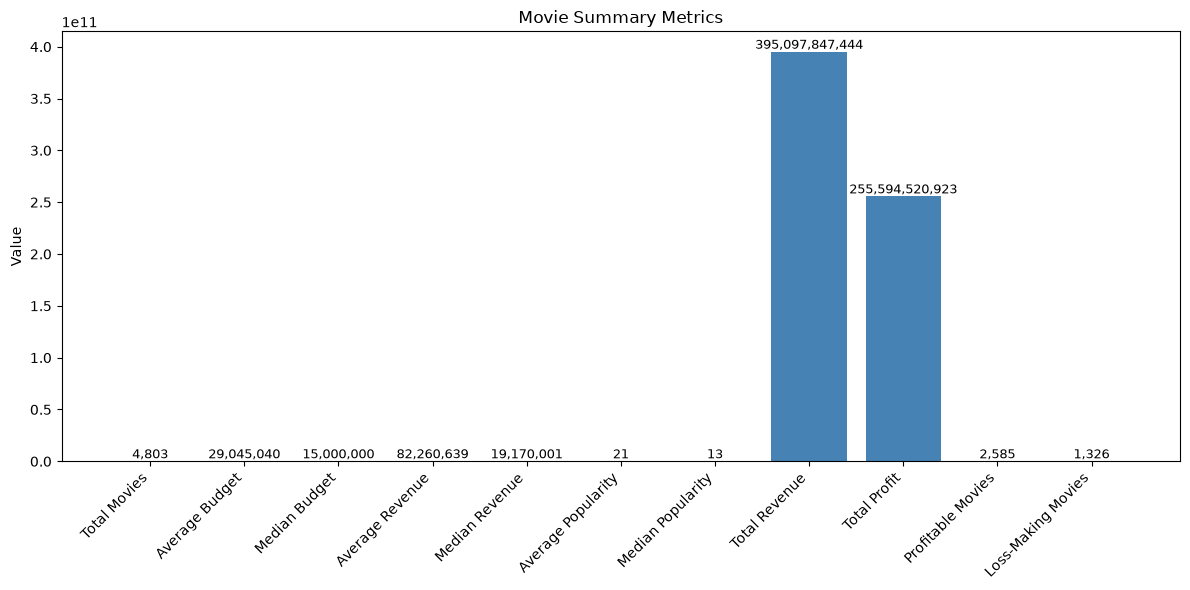

In [94]:
plt.figure(figsize=(12, 6))
bars = plt.bar(movie_summary["Metric"], movie_summary["Value"], color="steelblue")

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        rotation=0
    )

plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.title("Movie Summary Metrics")
plt.tight_layout()
plt.show()

# Business Insights

## Movie Portfolio

The analysis provides an overview of the size and composition of the movie portfolio and identifies whether movie production is concentrated within particular periods, genres, languages, or production regions.

## Financial Performance

Revenue, budget, profit, and ROI provide different perspectives on movie performance.

Revenue identifies commercial scale, while ROI measures the efficiency of capital deployment.

These metrics should be interpreted together rather than relying on revenue alone.

## Popularity

Popularity provides an indication of audience interest or attention but should not automatically be interpreted as financial success.

Movies with high popularity and low revenue represent an interesting segment for further investigation.

## Production

Production company and production country analysis identifies organizations and geographic markets with significant representation in the movie portfolio.

## Genre

Genre analysis identifies dominant content categories and allows comparison of financial and popularity performance across genres.

## Risk and Opportunity

Movies with:

- High budget and low revenue may represent financial risk.
- Low budget and high revenue may represent efficient capital deployment.
- High popularity and low revenue may indicate strong audience interest without corresponding commercial conversion.
- High revenue and low popularity may indicate commercially successful movies with relatively limited measured popularity.

## Key Analytical Principle

The Movie Master maintains a one-row-per-movie grain.

All movie-level financial metrics are therefore calculated without the duplication risk associated with artist, genre, language, keyword, company, and country bridge tables.